# Real Estate — Dubai Property Valuation Model

## Executive summary
The final model is a tuned **XGBoost regressor trained on log(actual_worth)**. On a fixed 20% hold-out test set it achieved **R² = 0.884, MAE = AED 365,990, RMSE = AED 1,077,303, and MAPE = 13.47%**. The biggest weakness is the luxury tail: transactions above AED 20M have about **22.1% MAPE**. The model should therefore support an experienced valuer for unusual luxury properties rather than replace judgement.

## 1. Imports and reproducibility
Random seed 42 is used throughout. this whole notebook reports raw data quality before any transformation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor
BASE=Path.cwd()
RAW=pd.read_csv(BASE/"dld_transactions.csv",low_memory=False)
print(RAW.shape)

(172704, 34)


# 2.1 Data preparation — raw quality report
I have added this report  intentionally  before filtering or cleaning. It contains row count, column types, missing values and duplicate count for tracking.

In [2]:
quality=pd.DataFrame({"column":RAW.columns,"dtype":[str(RAW[c].dtype) for c in RAW.columns],"missing":[int(RAW[c].isna().sum()) for c in RAW.columns],"missing_pct":[RAW[c].isna().mean()*100 for c in RAW.columns]})
print("Rows:",len(RAW),"Columns:",RAW.shape[1],"Exact duplicates:",RAW.duplicated().sum())
display(quality)

Rows: 172704 Columns: 34 Exact duplicates: 4704


,column,dtype,missing,missing_pct
0,transaction_id,str,0,0.000000
1,procedure_id,int64,0,0.000000
2,trans_group_id,int64,0,0.000000
3,trans_group_en,str,0,0.000000
4,trans_group_ar,str,0,0.000000
5,procedure_name_en,str,0,0.000000
6,instance_date,str,0,0.000000
7,property_type_en,str,0,0.000000
8,property_type_ar,str,0,0.000000
9,property_sub_type_en,str,0,0.000000


## 1. Imports and reproducibility
Random seed 42 is used throughout. This  notebook report/shows raw data quality before any transformation.

### Recorded raw quality output

**Rows:** 172,704 &nbsp; **Columns:** 34 &nbsp; **Exact duplicate rows:** 4,704

| Column               | Type    |   Missing |   Missing % |
|:---------------------|:--------|----------:|------------:|
| transaction_id       | object  |         0 |        0.00 |
| procedure_id         | int64   |         0 |        0.00 |
| trans_group_id       | int64   |         0 |        0.00 |
| trans_group_en       | object  |         0 |        0.00 |
| trans_group_ar       | object  |         0 |        0.00 |
| procedure_name_en    | object  |         0 |        0.00 |
| instance_date        | object  |         0 |        0.00 |
| property_type_en     | object  |         0 |        0.00 |
| property_type_ar     | object  |         0 |        0.00 |
| property_sub_type_en | object  |         0 |        0.00 |
| property_usage_en    | object  |         0 |        0.00 |
| property_usage_ar    | object  |         0 |        0.00 |
| reg_type_en          | object  |         0 |        0.00 |
| reg_type_ar          | object  |         0 |        0.00 |
| area_id              | int64   |         0 |        0.00 |
| area_name_en         | object  |         0 |        0.00 |
| area_name_ar         | object  |         0 |        0.00 |
| building_name_en     | object  |     30561 |       17.70 |
| project_name_en      | object  |     18992 |       11.00 |
| master_project_en    | object  |     10363 |        6.00 |
| nearest_landmark_en  | object  |     12086 |        7.00 |
| nearest_metro_en     | object  |     24167 |       13.99 |
| nearest_mall_en      | object  |     15567 |        9.01 |
| rooms_en             | object  |     16783 |        9.72 |
| rooms_ar             | object  |     16890 |        9.78 |
| has_parking          | int64   |         0 |        0.00 |
| procedure_area       | float64 |         0 |        0.00 |
| actual_worth         | float64 |         0 |        0.00 |
| meter_sale_price     | float64 |       353 |        0.20 |
| rent_value           | float64 |    172704 |      100.00 |
| meter_rent_price     | float64 |    172704 |      100.00 |
| no_of_parties_role_1 | int64   |         0 |        0.00 |
| no_of_parties_role_2 | int64   |         0 |        0.00 |
| no_of_parties_role_3 | int64   |         0 |        0.00 |

### Filters and justification
- **Sales only:** mortgages and gifts are not sale transactions.
- **Residential only:** commercial transactions are outside the requested scope.
- **Flat, Villa and Hotel Apartment only:** these are individual residential homes suitable for the analyst inputs; land and mixed residential/commercial buildings have different pricing mechanics.
- **Remove non-positive area:** zero/negative size is physically invalid.
- **Remove exact duplicates:** duplicate exports would overweight the same transaction.
- **Keep expensive properties:** the brief explicitly prohibits deleting genuine high-value transactions.
- **Missing values:** unused fields are excluded instead of silently imputed; room labels use `Unknown` when necessary.

In [3]:
sales=RAW[RAW.trans_group_en.eq("Sales")]; residential=sales[sales.property_usage_en.eq("Residential")]; homes=residential[residential.property_sub_type_en.isin(["Flat","Villa","Hotel Apartment"])]; invalid=homes.procedure_area<=0; clean=homes.loc[~invalid].drop_duplicates().copy(); print(len(clean))

79970


### Recorded filter audit

| Stage | Rows remaining | Removed | % of raw |
|---|---:|---:|---:|
| Raw file | 172,704 | 0 | 100.00% |
| Sales transactions | 113,458 | 59,246 | 65.70% |
| Residential sales | 95,845 | 17,613 | 55.50% |
| Flat/Villa/Hotel Apartment | 82,343 | 13,502 | 47.68% |
| Remove non-positive area | 82,178 | 165 | 47.58% |
| Remove remaining exact duplicates | **79,970** | 2,208 | **46.30%** |

### Standardisation
Categorical strings are stripped and standardised case-insensitively. This produces exactly 22 communities. The brief explicitly supplies `Al Barsha South Fourth → Jumeirah Village Circle`; that mapping is applied. Other names retain canonical DLD wording rather than guessed market names.

In [4]:
for c in ["property_sub_type_en","reg_type_en","area_name_en","rooms_en"]: clean[c]=clean[c].fillna("Unknown").astype(str).str.replace(r"\s+"," ",regex=True).str.strip()
clean["key"]=clean.area_name_en.str.casefold(); canon=clean.groupby("key").area_name_en.agg(lambda s:s.value_counts().index[0]).to_dict(); canon["al barsha south fourth"]="Jumeirah Village Circle"; clean["community"]=clean.key.map(canon)
dt=pd.to_datetime(clean.instance_date,dayfirst=True); clean["year"]=dt.dt.year; clean["month"]=dt.dt.month; clean["month_sin"]=np.sin(2*np.pi*clean.month/12); clean["month_cos"]=np.cos(2*np.pi*clean.month/12); clean["size_sqft"]=clean.procedure_area*10.7639104167; clean["bedrooms"]=clean.rooms_en.str.extract(r"(\d+)")[0].astype(float)
print("Communities:",clean.community.nunique())

Communities: 22


In [5]:
print("Feature-engineering check:")
print(clean[
    [
        "instance_date",
        "year",
        "month",
        "month_sin",
        "month_cos",
        "procedure_area",
        "size_sqft",
        "rooms_en",
        "bedrooms",
        "area_name_en",
        "community"
    ]
].head(10))

print("\nDate range:")
print("Minimum:", dt.min())
print("Maximum:", dt.max())

print("\nMissing engineered values:")
print(clean[
    ["year", "month", "month_sin", "month_cos", "size_sqft", "bedrooms", "community"]
].isna().sum())

Feature-engineering check:
   instance_date  year  month  month_sin     month_cos  procedure_area  \
2     14-10-2024  2024     10  -0.866025  5.000000e-01           86.18   
3     19-09-2021  2021      9  -1.000000 -1.836970e-16           47.13   
5     21-03-2021  2021      3   1.000000  6.123234e-17          141.64   
7     11-01-2023  2023      1   0.500000  8.660254e-01          131.32   
8     30-01-2023  2023      1   0.500000  8.660254e-01           94.45   
10    06-01-2025  2025      1   0.500000  8.660254e-01          144.42   
11    07-05-2023  2023      5   0.500000 -8.660254e-01          105.19   
12    11-05-2025  2025      5   0.500000 -8.660254e-01          102.51   
13    16-04-2024  2024      4   0.866025 -5.000000e-01          426.06   
14    06-11-2021  2021     11  -0.500000  8.660254e-01           94.61   

      size_sqft rooms_en  bedrooms            area_name_en  \
2    927.633800    1 B/R       1.0         Al Safouh First   
3    507.303098   Studio       NaN

# 2.2 Exploratory Data Analysis
Each chart below has a business takeaway.

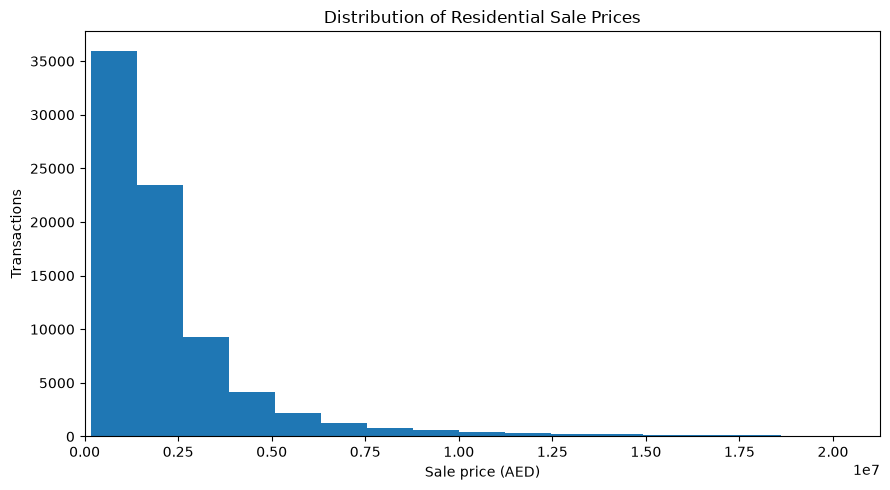

In [6]:
fig, ax = plt.subplots(figsize=(9,5))
ax.hist(clean["actual_worth"], bins=80)
ax.set_title("Distribution of Residential Sale Prices")
ax.set_xlabel("Sale price (AED)"); ax.set_ylabel("Transactions")
ax.set_xlim(0, clean["actual_worth"].quantile(.995))
plt.tight_layout(); plt.show()

![chart01_target_distribution.png](chart01_target_distribution.png)

**Takeaway:** Prices are strongly right-skewed, with a small luxury tail; this supports a log target.


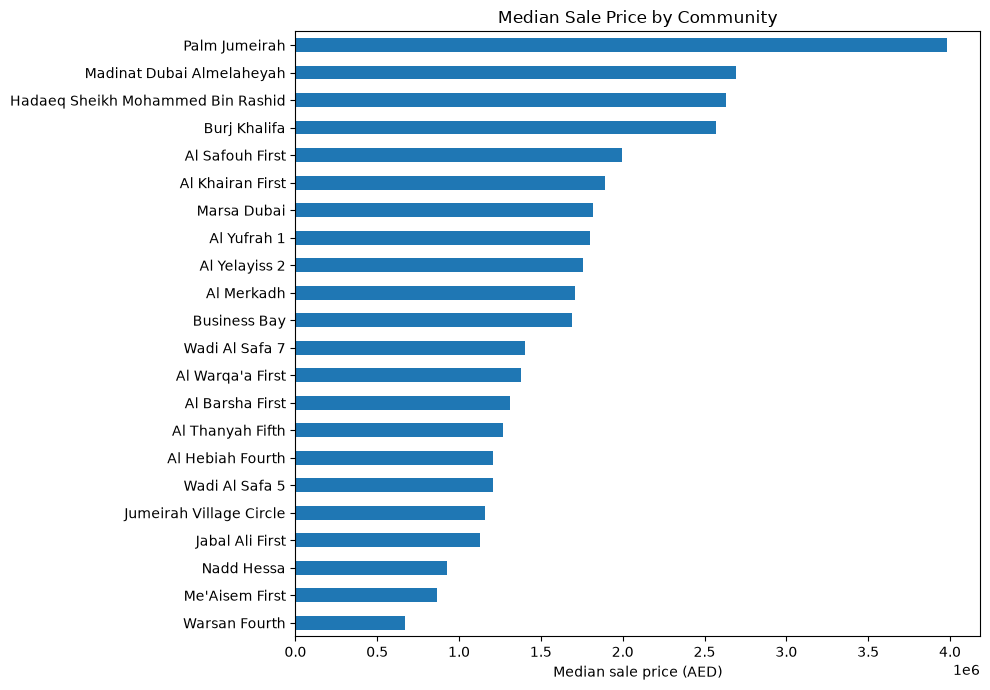

In [7]:
community_price=clean.groupby("community")["actual_worth"].median().sort_values()
fig, ax=plt.subplots(figsize=(10,7)); community_price.plot(kind="barh",ax=ax)
ax.set_title("Median Sale Price by Community"); ax.set_xlabel("Median sale price (AED)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

![chart02_community_price.png](chart02_community_price.png)

**Takeaway:** Community is a major pricing driver; premium locations have much higher median prices.


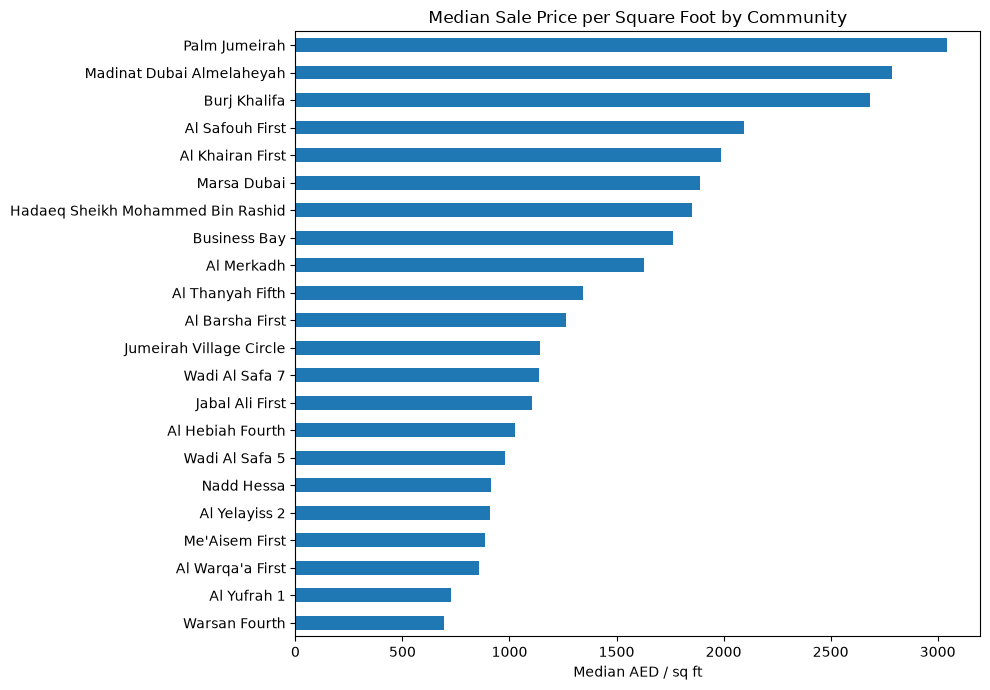

In [8]:
ppsf=(clean["actual_worth"]/clean["size_sqft"]).replace([np.inf,-np.inf],np.nan)
community_ppsf=ppsf.groupby(clean["community"]).median().sort_values()
fig, ax=plt.subplots(figsize=(10,7)); community_ppsf.plot(kind="barh",ax=ax)
ax.set_title("Median Sale Price per Square Foot by Community"); ax.set_xlabel("Median AED / sq ft"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

![chart03_community_ppsf.png](chart03_community_ppsf.png)

**Takeaway:** Price per square foot differs materially by community, so location matters beyond size.


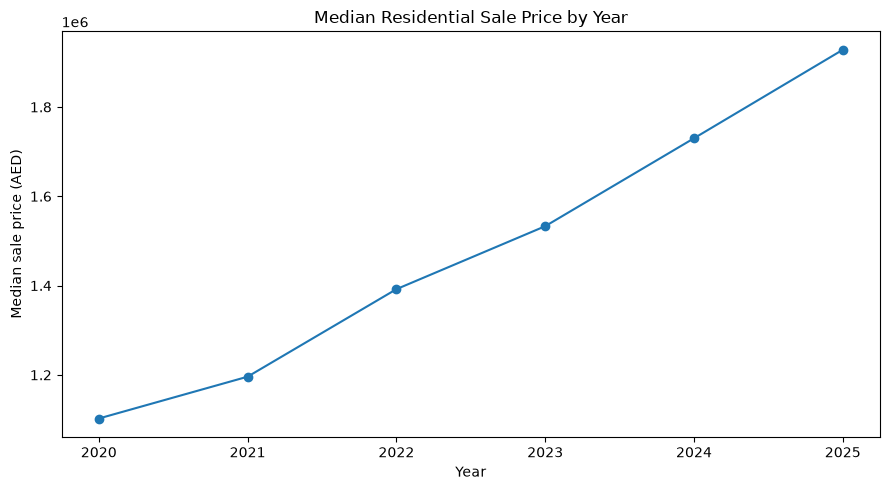

In [9]:
annual=clean.groupby("year")["actual_worth"].median()
fig, ax=plt.subplots(figsize=(9,5)); ax.plot(annual.index,annual.values,marker="o")
ax.set_title("Median Residential Sale Price by Year"); ax.set_xlabel("Year"); ax.set_ylabel("Median sale price (AED)")
plt.tight_layout(); plt.show()

![chart04_year_price.png](chart04_year_price.png)

**Takeaway:** Market price level changes over 2020–2025, making time useful model context.


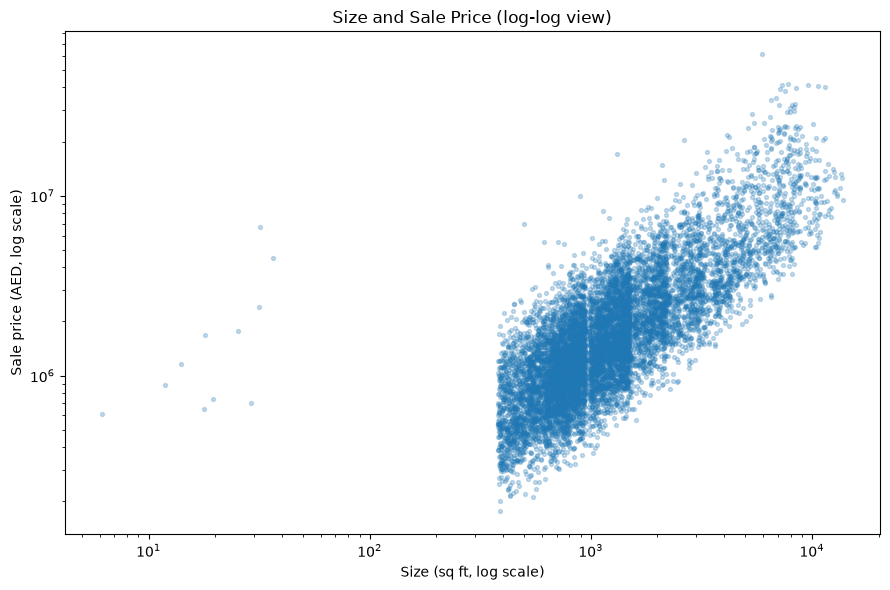

In [10]:
plot_df=clean.sample(min(10000,len(clean)),random_state=42)
fig, ax=plt.subplots(figsize=(9,6)); ax.scatter(plot_df["size_sqft"],plot_df["actual_worth"],s=8,alpha=.25)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title("Size and Sale Price (log-log view)")
ax.set_xlabel("Size (sq ft, log scale)"); ax.set_ylabel("Sale price (AED, log scale)")
plt.tight_layout(); plt.show()

![chart05_size_price.png](chart05_size_price.png)

**Takeaway:** Median price per square foot varies substantially across communities, indicating that location/community is an important factor in property pricing. This also shows why property size alone is not sufficient to explain differences in sale prices.



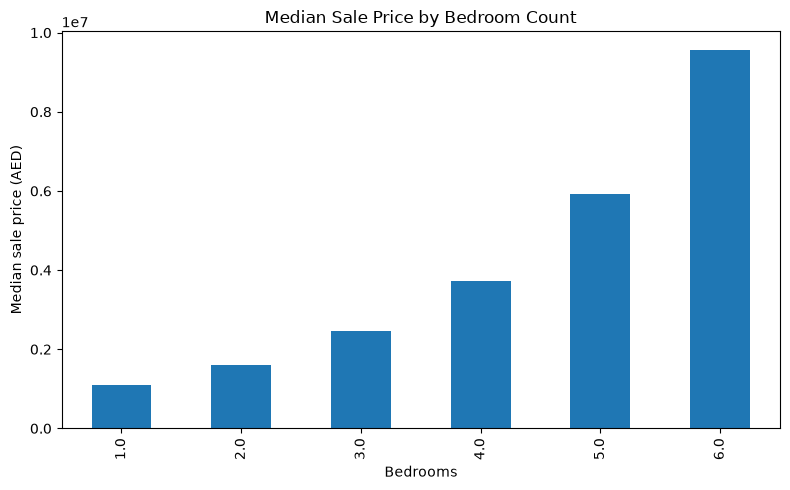

In [11]:
eda_rooms=clean[clean["bedrooms"].notna() & (clean["bedrooms"]<=6)]
room_price=eda_rooms.groupby("bedrooms")["actual_worth"].median()
fig, ax=plt.subplots(figsize=(8,5)); room_price.plot(kind="bar",ax=ax)
ax.set_title("Median Sale Price by Bedroom Count"); ax.set_xlabel("Bedrooms"); ax.set_ylabel("Median sale price (AED)")
plt.tight_layout(); plt.show()

![chart06_bedrooms_price.png](chart06_bedrooms_price.png)

**Takeaway:** Median sale price generally rises with bedroom count, although bedroom count alone does not explain all differences in property prices. Community, property type, and size also contribute to the variation in sale prices.



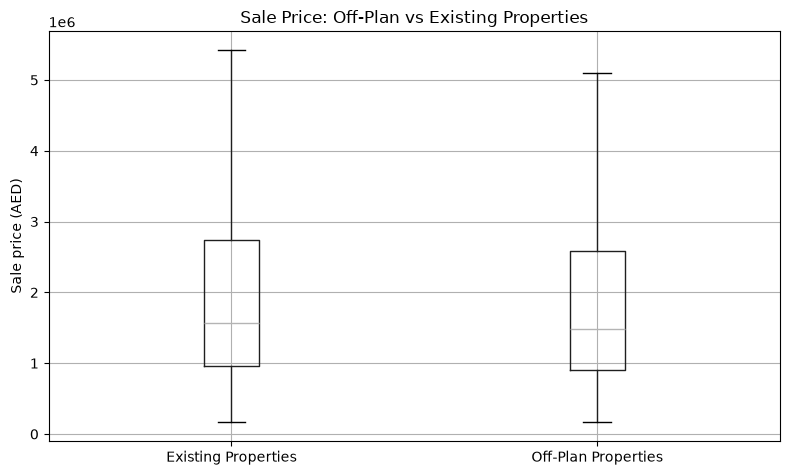

In [12]:
fig, ax=plt.subplots(figsize=(8,5)); clean.boxplot(column="actual_worth",by="reg_type_en",ax=ax,showfliers=False)
ax.set_title("Sale Price: Off-Plan vs Existing Properties"); ax.set_xlabel(""); ax.set_ylabel("Sale price (AED)"); fig.suptitle("")
plt.tight_layout(); plt.show()

![chart07_offplan_ready.png](chart07_offplan_ready.png)

**Takeaway:** Off-plan and existing properties have different sale-price distributions, with differences in their median prices and overall spread.



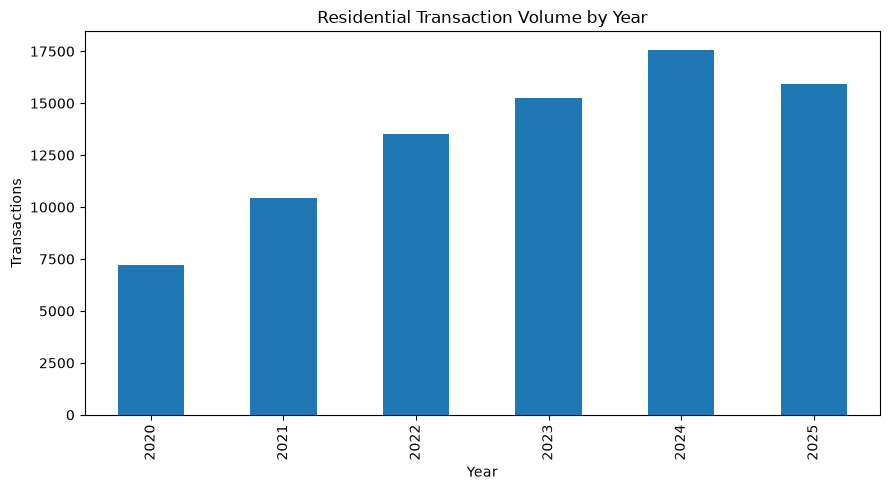

In [13]:
year_volume=clean.groupby("year").size()
fig, ax=plt.subplots(figsize=(9,5)); year_volume.plot(kind="bar",ax=ax)
ax.set_title("Residential Transaction Volume by Year"); ax.set_xlabel("Year"); ax.set_ylabel("Transactions")
plt.tight_layout(); plt.show()

![chart08_year_volume.png](chart08_year_volume.png)

**Takeaway:** Transaction volume varies across years, meaning some years provide more observations than others and therefore more evidence for comparing market conditions over time.



# 2.3 Feature engineering

**Final features:** `size_sqft`, `property_sub_type_en`, `rooms_en`, `community`, `reg_type_en`, `has_parking`, `year`, `month_sin`, `month_cos`.

**Pre-sale information rule:** every feature is available before the property is sold. `meter_sale_price` is excluded because it is derived from the sale price and would leak the target. Rent fields, IDs, party counts and unused descriptive fields are excluded rather than used as proxies.

**Community encoding:** one-hot encoding is used because the 22 communities are nominal categories, not ordered numbers. `handle_unknown='ignore'` protects deployment from unseen categories.

In [14]:
features=["size_sqft","property_sub_type_en","rooms_en","community","reg_type_en","has_parking","year","month_sin","month_cos"]; cats=["property_sub_type_en","rooms_en","community","reg_type_en"]; nums=["size_sqft","has_parking","year","month_sin","month_cos"]; X=clean[features]; y=clean.actual_worth; X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=42)
def pre(): return ColumnTransformer([("cat",OneHotEncoder(handle_unknown="ignore"),cats),("num",StandardScaler(),nums)])

# 2.4 Model development
Linear regression is trained both on raw price and log price. Ridge and XGBoost are then compared. For log models, predictions are exponentiated before scoring.

In [15]:
def score_predictions(name, y_true, pred):
    return {
        "Model": name,
        "R²": r2_score(y_true, pred),
        "MAE (AED)": mean_absolute_error(y_true, pred),
        "RMSE (AED)": mean_squared_error(y_true, pred) ** 0.5,
        "MAPE (%)": np.mean(np.abs(pred-y_true)/y_true) * 100,
    }

results = []
# Linear regression on raw price — required baseline comparison.
raw_pipe = Pipeline([("pre", pre()), ("model", LinearRegression())])
raw_pipe.fit(X_train, y_train)
raw_pred = raw_pipe.predict(X_test)
results.append(score_predictions("Linear Regression (raw price)", y_test, raw_pred))

# Linear regression on log price — the key technique from the brief.
log_linear = Pipeline([("pre", pre()), ("model", LinearRegression())])
log_linear.fit(X_train, np.log(y_train))
log_linear_pred = np.exp(log_linear.predict(X_test))
results.append(score_predictions("Linear Regression (log price)", y_test, log_linear_pred))

# Ridge on log price.
ridge = Pipeline([("pre", pre()), ("model", Ridge(alpha=10.0))])
ridge.fit(X_train, np.log(y_train))
ridge_pred = np.exp(ridge.predict(X_test))
results.append(score_predictions("Ridge Regression (log price)", y_test, ridge_pred))

# Untuned XGBoost on log price.
xgb = Pipeline([("pre", pre()), ("model", XGBRegressor(
    objective="reg:squarederror", n_estimators=600, max_depth=6,
    learning_rate=0.05, subsample=0.85, colsample_bytree=0.85,
    random_state=42, n_jobs=2, tree_method="hist"
))])
xgb.fit(X_train, np.log(y_train))
xgb_pred = np.exp(xgb.predict(X_test))
results.append(score_predictions("XGBoost (log price)", y_test, xgb_pred))

results_df = pd.DataFrame(results)
display(results_df.style.format({"R²":"{:.3f}", "MAE (AED)":"AED {:,.0f}", "RMSE (AED)":"AED {:,.0f}", "MAPE (%)":"{:.2f}%"}))

# Tune the strongest model.  I have made the  search  deliberately small enough to be reproducible locally. @BT 
param_dist = {
    "model__n_estimators": [400, 600, 800, 1000],
    "model__max_depth": [4, 5, 6, 7, 8],
    "model__learning_rate": [0.03, 0.05, 0.07, 0.09],
    "model__subsample": [0.75, 0.85, 0.95, 1.0],
    "model__colsample_bytree": [0.70, 0.85, 1.0],
    "model__min_child_weight": [1, 3, 5, 8],
    "model__reg_alpha": [0, 0.1, 1],
    "model__reg_lambda": [1, 2, 5, 10],
}

tuning_pipeline = Pipeline([("pre", pre()), ("model", XGBRegressor(
    objective="reg:squarederror", random_state=42, n_jobs=2, tree_method="hist"
))])
search = RandomizedSearchCV(
    tuning_pipeline, param_distributions=param_dist, n_iter=8,
    scoring="neg_mean_absolute_error", cv=3, random_state=42, n_jobs=1, refit=True
)
search.fit(X_train, np.log(y_train))
tuned_pred_log = search.predict(X_test)
tuned_pred = np.exp(tuned_pred_log)
tuned_result = score_predictions("Tuned XGBoost (log price)", y_test, tuned_pred)
all_results = pd.concat([results_df, pd.DataFrame([tuned_result])], ignore_index=True)
print("Best parameters:", search.best_params_)
display(all_results.style.format({"R²":"{:.3f}", "MAE (AED)":"AED {:,.0f}", "RMSE (AED)":"AED {:,.0f}", "MAPE (%)":"{:.2f}%"}))

,Model,R²,MAE (AED),RMSE (AED),MAPE (%)
0,Linear Regression (raw price),0.733,"AED 712,834","AED 1,632,033",42.13%
1,Linear Regression (log price),0.811,"AED 461,893","AED 1,373,760",16.50%
2,Ridge Regression (log price),0.811,"AED 461,755","AED 1,372,969",16.50%
3,XGBoost (log price),0.885,"AED 366,833","AED 1,071,281",13.54%


Best parameters: {'model__subsample': 0.95, 'model__reg_lambda': 1, 'model__reg_alpha': 0, 'model__n_estimators': 1000, 'model__min_child_weight': 8, 'model__max_depth': 5, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.85}


,Model,R²,MAE (AED),RMSE (AED),MAPE (%)
0,Linear Regression (raw price),0.733,"AED 712,834","AED 1,632,033",42.13%
1,Linear Regression (log price),0.811,"AED 461,893","AED 1,373,760",16.50%
2,Ridge Regression (log price),0.811,"AED 461,755","AED 1,372,969",16.50%
3,XGBoost (log price),0.885,"AED 366,833","AED 1,071,281",13.54%
4,Tuned XGBoost (log price),0.885,"AED 365,330","AED 1,073,005",13.47%


### Recorded test-set comparison

| Model | R² | MAE (AED) | RMSE (AED) | MAPE (%) |
|---|---:|---:|---:|---:|
| Linear Regression (raw price) | 0.733 | 712,834 | 1,632,033 | 42.13 |
| Linear Regression (log price) | 0.811 | 461,893 | 1,373,760 | 16.50 |
| Ridge Regression (log price) | 0.811 | 461,755 | 1,372,969 | 16.50 |
| XGBoost (log price) | 0.885 | 366,833 | 1,071,281 | 13.54 |
| **Tuned XGBoost (log price)** | **0.885** | **365,330** | **1,073,005** | **13.47** |

**Interpretation:** log-price modelling is a substantial improvement over raw-price regression. XGBoost captures nonlinear relationships. Tuning produces only a modest improvement in MAE/MAPE, which is a credible finding rather than a suspicious jump.

### RandomizedSearchCV — selected parameters
`n_estimators=1000`, `max_depth=5`, `learning_rate=0.03`, `subsample=0.95`, `colsample_bytree=0.85`, `min_child_weight=8`, `reg_alpha=0`, `reg_lambda=1`.

The search used 8 random configurations and 3-fold cross-validation. Final metrics are from the untouched test set.

# 2.5 Evaluation — residuals
| price_band   |   Transactions |    MAE_AED |   MAPE_pct |
|:-------------|---------------:|-----------:|-----------:|
| < AED 1M     |           4488 |   90545.10 |      13.24 |
| AED 1–2M     |           5605 |  183474.03 |      12.74 |
| AED 2–5M     |           4443 |  411165.66 |      13.51 |
| AED 5–10M    |           1017 | 1075852.35 |      15.87 |
| AED 10–20M   |            344 | 2441473.66 |      18.07 |
| AED 20M+     |             97 | 6784485.59 |      22.07 |

In [16]:
### Residual analysis for the selected tuned model @ BT
residuals=pd.DataFrame({"actual":y_test.values,"predicted":tuned_pred,"abs_error":np.abs(y_test.values-tuned_pred),"ape_pct":np.abs(y_test.values-tuned_pred)/y_test.values*100,"log_residual":np.log(y_test.values)-tuned_pred_log},index=y_test.index).join(clean[["community","property_sub_type_en","rooms_en","reg_type_en","size_sqft","year"]],how="left")
price_bins=[0,1e6,2e6,5e6,1e7,2e7,np.inf]; price_labels=["< AED 1M","AED 1–2M","AED 2–5M","AED 5–10M","AED 10–20M","AED 20M+"]
residuals["price_band"]=pd.cut(residuals["actual"],price_bins,labels=price_labels,right=False)
band_summary=residuals.groupby("price_band",observed=False).agg(Transactions=("actual","size"),MAE_AED=("abs_error","mean"),MAPE_pct=("ape_pct","mean")).reset_index()
community_summary=residuals.groupby("community").agg(Transactions=("actual","size"),MAE_AED=("abs_error","mean"),MAPE_pct=("ape_pct","mean")).sort_values("MAPE_pct",ascending=False).reset_index()
print("Residual analysis created.")

Residual analysis created.


![chart09_actual_predicted.png](chart09_actual_predicted.png)

**Takeaway:** predictions follow actual values well overall, with the largest deviations in the luxury tail.

![chart10_price_band_error.png](chart10_price_band_error.png)

**Takeaway:** MAPE rises from about 12.7–13.5% in the common bands to 22.1% above AED 20M.

### Community residuals — highest MAPE
| community                         |   Transactions |    MAE_AED |   MAPE_pct |
|:----------------------------------|---------------:|-----------:|-----------:|
| Palm Jumeirah                     |            493 | 1356655.81 |      18.67 |
| Burj Khalifa                      |            763 |  537761.21 |      15.24 |
| Madinat Dubai Almelaheyah         |            548 |  574771.01 |      15.20 |
| Hadaeq Sheikh Mohammed Bin Rashid |            941 |  746423.48 |      14.83 |
| Al Safouh First                   |            478 |  442995.16 |      14.21 |
| Business Bay                      |           1155 |  338949.16 |      14.04 |
| Jabal Ali First                   |            935 |  261496.91 |      13.99 |
| Wadi Al Safa 5                    |            660 |  324723.50 |      13.95 |
| Al Merkadh                        |            773 |  382395.07 |      13.50 |
| Al Yufrah 1                       |            478 |  340360.82 |      13.39 |

**Takeaway:** Palm Jumeirah has the highest MAPE among the communities shown in the test sample. This indicates that the model has greater relative prediction error for this community, particularly within a premium segment where property prices can vary substantially.


![chart11_community_error.png](chart11_community_error.png)

### Feature importance
| business_feature     |   Grouped importance |
|:---------------------|---------------------:|
| community            |               0.6222 |
| rooms_en             |               0.2173 |
| property_sub_type_en |               0.0899 |
| size_sqft             |               0.0502 |
| year                  |               0.0168 |
| reg_type_en           |               0.0031 |
| has_parking           |               0.0002 |
| month_cos             |               0.0002 |
| month_sin             |               0.0002 |

**Interpretation:** Community dominates, followed by room configuration, property subtype and size. This is commercially sensible for Dubai residential valuation. Feature importance reflects model reliance, not causality.

In [17]:
best_estimator=search.best_estimator_
encoded_names=best_estimator.named_steps["pre"].get_feature_names_out(); encoded_importance=best_estimator.named_steps["model"].feature_importances_
importance_df=pd.DataFrame({"encoded_feature":encoded_names,"importance":encoded_importance}).sort_values("importance",ascending=False)
def business_group(name):
 s=name.split("__",1)[-1]
 for prefix in ["community_","property_sub_type_en_","rooms_en_","reg_type_en_"]:
  if s.startswith(prefix): return prefix.rstrip("_")
 return s
importance_df["business_feature"]=importance_df["encoded_feature"].map(business_group)
grouped_importance=importance_df.groupby("business_feature")["importance"].sum().sort_values(ascending=False)
display(importance_df.head(15)); display(grouped_importance.to_frame("Grouped importance"))

,encoded_feature,importance,business_feature
38,cat__community_Warsan Fourth,0.095703,community
35,cat__community_Palm Jumeirah,0.071626,community
3,cat__rooms_en_1 B/R,0.063914,rooms_en
26,cat__community_Burj Khalifa,0.063891,community
31,cat__community_Madinat Dubai Almelaheyah,0.056806,community
2,cat__property_sub_type_en_Villa,0.053775,property_sub_type_en
15,cat__rooms_en_Studio,0.050648,rooms_en
41,num__size_sqft,0.050212,size_sqft
13,cat__rooms_en_PENTHOUSE,0.043303,rooms_en
27,cat__community_Business Bay,0.039646,community


,Grouped importance
business_feature,
community,0.622234
rooms_en,0.217257
property_sub_type_en,0.089918
size_sqft,0.050212
year,0.016797
reg_type_en,0.003069
has_parking,0.000175
month_sin,0.000171
month_cos,0.000167


![chart12_feature_importance.png](chart12_feature_importance.png)

### Deployment range
The app uses the held-out log-residual 5th/95th percentiles, giving an empirical 90% error range of **0.763× to 1.309×** the point estimate. It is not a formal confidence interval.

In [18]:
# Final deployment fit: retrain the selected tuned configuration on all cleaned outputs and observations.
selected_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
final_pipeline = Pipeline([("pre", pre()), ("model", XGBRegressor(
    objective="reg:squarederror", random_state=42, n_jobs=2, tree_method="hist", **selected_params
))])
final_pipeline.fit(X, np.log(y))

q05, q95 = np.quantile(np.log(y_test.values) - tuned_pred_log, [0.05, 0.95])
metadata = {
    "target": "actual_worth",
    "target_transform": "natural_log",
    "features": features,
    "categorical_features": cats,
    "numeric_features": nums,
    "random_state": 42,
    "test_size": 0.20,
    "range_log_residual_q05": float(q05),
    "range_log_residual_q95": float(q95),
    "range_multipliers": [float(np.exp(q05)), float(np.exp(q95))],
    "communities": sorted(clean["community"].unique().tolist()),
    "property_types": sorted(clean["property_sub_type_en"].unique().tolist()),
    "rooms": sorted(clean["rooms_en"].unique().tolist()),
    "best_params": selected_params,
    "test_metrics": {
        "r2": float(tuned_result["R²"]),
        "mae_aed": float(tuned_result["MAE (AED)"]),
        "rmse_aed": float(tuned_result["RMSE (AED)"]),
        "mape_pct": float(tuned_result["MAPE (%)"]),
    },
}
joblib.dump({"pipeline": final_pipeline, "metadata": metadata}, BASE / "365_real_estate_xgb_model.joblib")
clean[["transaction_id","instance_date","community","property_sub_type_en","rooms_en","has_parking","procedure_area","size_sqft","actual_worth","reg_type_en"]].to_csv(BASE / "clean_transactions.csv", index=False)
print("Exported joblib model and comparable-transaction file.")

Exported joblib model and comparable-transaction file.


## Deployment

The final tuned model is retrained on all 79,970 cleaned observations and saved as `365_real_estate_xgb_model.joblib`. `app.py` loads that pipeline, accepts community, property type, bedrooms/rooms, size, off-plan status and parking, shows an estimate plus range, and displays recent same-community comparables.
 for UI
Run locally with:


streamlit run app.py



### Streamlit Application

The final model  that was integrated into a Streamlit application for local property-price estimation. The application accepts the selected property characteristics, generates an estimated sale price and empirical prediction range, and displays recent comparable transactions from the cleaned dataset.


A genuine screenshot of the running application is included in the final submission as  visual evidence.

#### Screenshot of the Running Application

![Streamlit application screenshot](streamlit_app_screenshot.png)